In [202]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller,kpss
import numpy as np
from statsmodels.graphics.tsaplots import plot_acf


In [149]:
data = pd.read_csv("Electric_Production.csv")

In [150]:
data.shape

(397, 2)

In [151]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   DATE        397 non-null    object 
 1   IPG2211A2N  397 non-null    float64
dtypes: float64(1), object(1)
memory usage: 6.3+ KB


In [152]:
data.head(20)

,DATE,IPG2211A2N
0,1/1/1985,72.5052
1,2/1/1985,70.6720
2,3/1/1985,62.4502
3,4/1/1985,57.4714
4,5/1/1985,55.3151
5,6/1/1985,58.0904
6,7/1/1985,62.6202
7,8/1/1985,63.2485
8,9/1/1985,60.5846
9,10/1/1985,56.3154


In [153]:
data.tail(20)

,DATE,IPG2211A2N
377,6/1/2016,104.0375
378,7/1/2016,114.5397
379,8/1/2016,115.5159
380,9/1/2016,102.7637
381,10/1/2016,91.4867
382,11/1/2016,92.8900
383,12/1/2016,112.7694
384,1/1/2017,114.8505
385,2/1/2017,99.4901
386,3/1/2017,101.0396


In [154]:
data.describe()

,IPG2211A2N
count,397.000000
mean,88.847218
std,15.387834
min,55.315100
25%,77.105200
50%,89.779500
75%,100.524400
max,129.404800


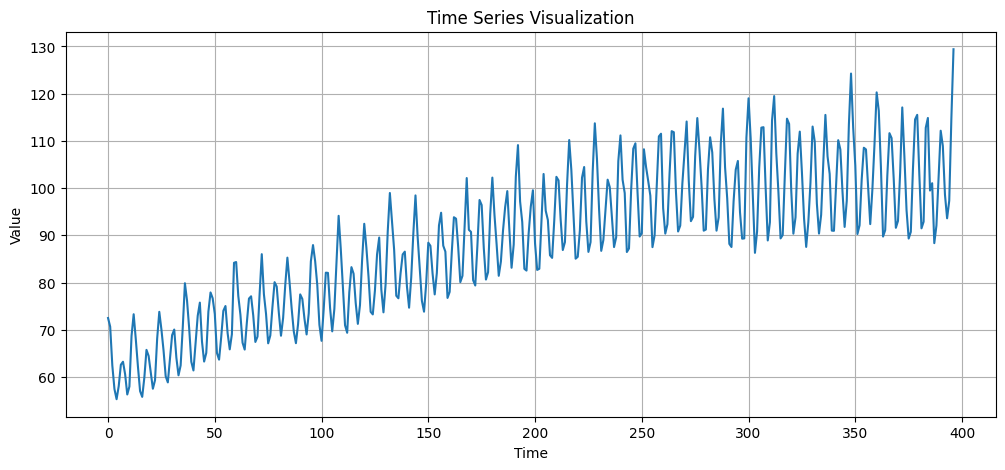

In [155]:
plt.figure(figsize=(12, 5))
plt.plot(data['IPG2211A2N'])

plt.title("Time Series Visualization")
plt.xlabel("Time")
plt.ylabel("Value")
plt.grid(True)
plt.show()

In [156]:
result = adfuller(data['IPG2211A2N'].dropna())

C:\Users\hp\AppData\Local\Temp\ipykernel_22924\487924050.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(data['IPG2211A2N'].dropna())


In [157]:
print("ADF Statistic:", result[0])
print("p-value:", result[1])
print("Critical Values:", result[4])
#The series is non-stationary according to the ADF test.

ADF Statistic: -2.25699035004725
p-value: 0.18621469116586592
Critical Values: {'1%': np.float64(-3.4476305904172904), '5%': np.float64(-2.869155980820355), '10%': np.float64(-2.570827146203181)}


In [158]:
result = kpss(data['IPG2211A2N'].dropna(), regression='c', nlags='auto')


C:\Users\hp\AppData\Local\Temp\ipykernel_22924\536083444.py:1: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  result = kpss(data['IPG2211A2N'].dropna(), regression='c', nlags='auto')
C:\Users\hp\AppData\Local\Temp\ipykernel_22924\536083444.py:1: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = kpss(data['IPG2211A2N'].dropna(), regression='c', nlags='auto')


In [ ]:
#on applique la differenciation
data["IPG2211A2N_diff"] = data["IPG2211A2N"].diff()

In [160]:
print("Statistique KPSS :", result[0])
print("p-value :", result[1])
print("Valeurs critiques :", result[3])
#On rehette la stationnarite

Statistique KPSS : 3.5315970094994853
p-value : 0.01
Valeurs critiques : {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}


In [162]:
data.columns

Index(['DATE', 'IPG2211A2N'], dtype='object')

In [163]:
#on applique la differenciation
data["IPG2211A2N_diff"] = data["IPG2211A2N"].diff()

In [164]:
data.head(10)

,DATE,IPG2211A2N,IPG2211A2N_diff
0,1/1/1985,72.5052,NaN
1,2/1/1985,70.6720,-1.8332
2,3/1/1985,62.4502,-8.2218
3,4/1/1985,57.4714,-4.9788
4,5/1/1985,55.3151,-2.1563
5,6/1/1985,58.0904,2.7753
6,7/1/1985,62.6202,4.5298
7,8/1/1985,63.2485,0.6283
8,9/1/1985,60.5846,-2.6639
9,10/1/1985,56.3154,-4.2692


<Axes: title={'center': 'Série différenciée'}>

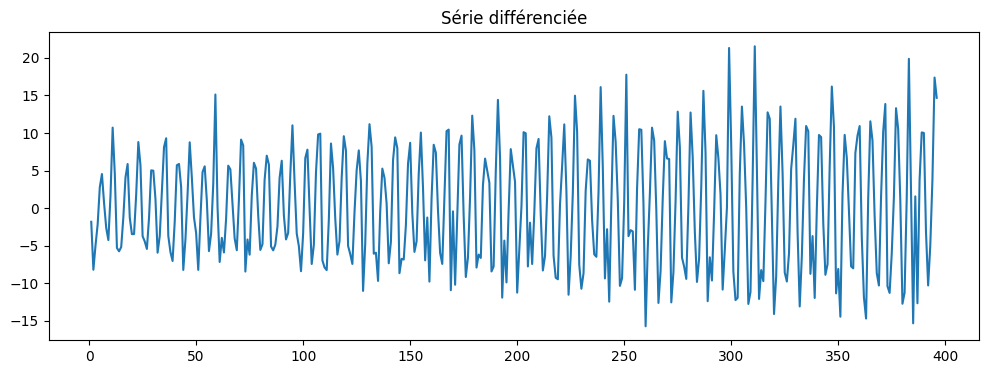

In [165]:
data["IPG2211A2N_diff"].plot(figsize=(12, 4), title="Série différenciée")

In [ ]:
#ADF TEST
result = adfuller(data['IPG2211A2N_diff'].dropna())
print("ADF Statistic:", result[0])
print("p-value:", result[1])
print("Critical Values:", result[4])
#on rejette l H0 car la serie est stationnaire

ADF Statistic: -7.104890882267312
p-value: 4.0777865655394095e-10
Critical Values: {'1%': np.float64(-3.4476305904172904), '5%': np.float64(-2.869155980820355), '10%': np.float64(-2.570827146203181)}


C:\Users\hp\AppData\Local\Temp\ipykernel_22924\1647411518.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(data['IPG2211A2N_diff'].dropna())


In [169]:
result = kpss(data['IPG2211A2N_diff'].dropna(), regression='c', nlags='auto')
print("Statistique KPSS :", result[0])
print("p-value :", result[1])
print("Valeurs critiques :", result[3])
#on ne rejette pas la stationnarite

Statistique KPSS : 0.14518934657460816
p-value : 0.1
Valeurs critiques : {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}


C:\Users\hp\AppData\Local\Temp\ipykernel_22924\3320247426.py:1: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  result = kpss(data['IPG2211A2N_diff'].dropna(), regression='c', nlags='auto')
C:\Users\hp\AppData\Local\Temp\ipykernel_22924\3320247426.py:1: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = kpss(data['IPG2211A2N_diff'].dropna(), regression='c', nlags='auto')


In [201]:
data.columns


Index(['DATE', 'IPG2211A2N', 'IPG2211A2N_diff'], dtype='object')

<Axes: >

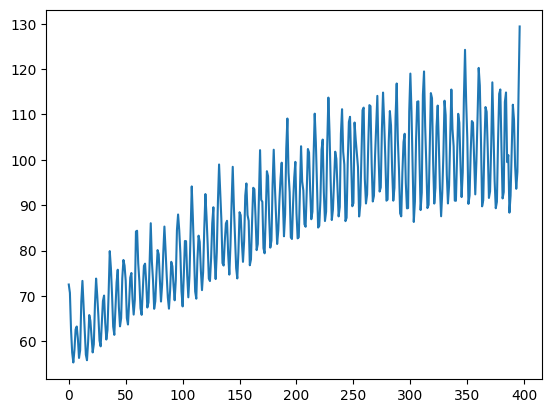

In [204]:
data["IPG2211A2N"].plot()

In [205]:
data["IPG2211A2N_log"] = np.log(data["IPG2211A2N"])

<Axes: >

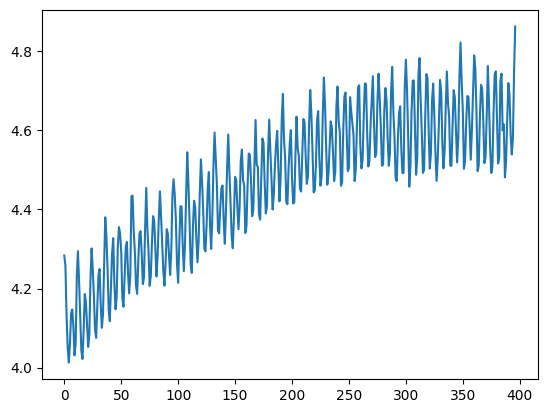

In [206]:
data["IPG2211A2N_log"].plot()

In [207]:
data["IPG2211A2N_log_diff"] = data["IPG2211A2N_log"].diff()

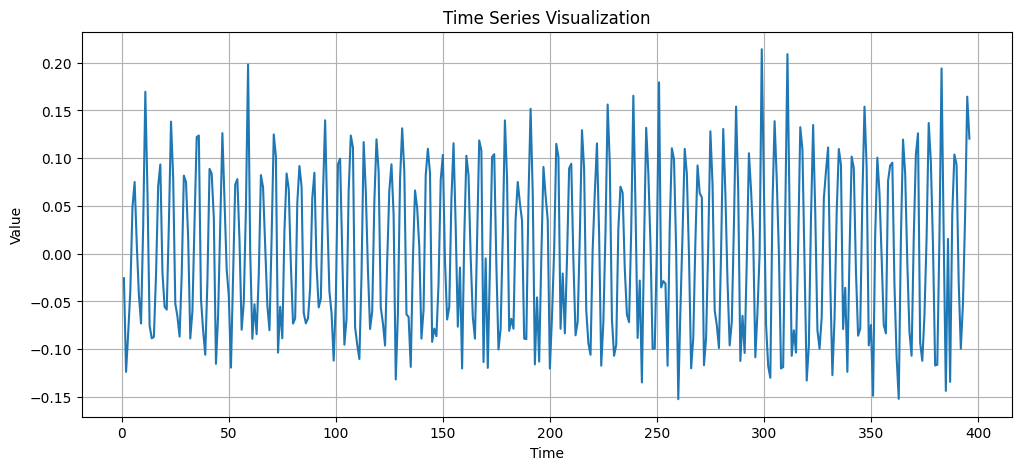

In [210]:
plt.figure(figsize=(12, 5))
plt.plot(data['IPG2211A2N_log_diff'])

plt.title("Time Series Visualization")
plt.xlabel("Time")
plt.ylabel("Value")
plt.grid(True)
plt.show()

In [211]:
#ADF TEST
result = adfuller(data['IPG2211A2N_log_diff'].dropna())
print("ADF Statistic:", result[0])
print("p-value:", result[1])
print("Critical Values:", result[4])
#on rejette l H0 car la serie est stationnaire

ADF Statistic: -6.748333370019134
p-value: 2.995161498116004e-09
Critical Values: {'1%': np.float64(-3.4476305904172904), '5%': np.float64(-2.869155980820355), '10%': np.float64(-2.570827146203181)}


C:\Users\hp\AppData\Local\Temp\ipykernel_22924\2899120899.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(data['IPG2211A2N_log_diff'].dropna())


In [212]:
result = kpss(data['IPG2211A2N_log_diff'].dropna(), regression='c', nlags='auto')
print("Statistique KPSS :", result[0])
print("p-value :", result[1])
print("Valeurs critiques :", result[3])
#on ne rejette pas la stationnarite

Statistique KPSS : 0.11412038097885754
p-value : 0.1
Valeurs critiques : {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}


C:\Users\hp\AppData\Local\Temp\ipykernel_22924\2802917123.py:1: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  result = kpss(data['IPG2211A2N_log_diff'].dropna(), regression='c', nlags='auto')
C:\Users\hp\AppData\Local\Temp\ipykernel_22924\2802917123.py:1: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = kpss(data['IPG2211A2N_log_diff'].dropna(), regression='c', nlags='auto')
